# Project 03 · Exotic Barrier Option Pricing & Delta–Vega Hedging


> **Reproducibility:** All values are simulated or assumed; these are educational pricing and risk-management demonstrations, not production trade recommendations. Re-run the cells from top to bottom.

> **How to run:** Open from the repository root (or `notebooks/`); the first code cell configures the engine import path. Install packages with `pip install -r requirements.txt`.


In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'engines').exists():
    root = root.parent
assert (root / 'engines').exists(), 'Launch Jupyter from the repository root or notebooks folder'
sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize':(10,4.5),'axes.grid':True})


## Trading mandate and market conventions

**Source:** `SPOILER_Project_Equity_derivatives.html`, **Exotic Trader: Pricing and Hedging an Exotic Barrier Option**.

The client owns an up-and-out European call, which pays \(\max(S_T-K,0)\) **only if** the underlying has not touched the upper barrier. The trading desk is **short** the option and dynamically hedges delta with stock and vega with a vanilla call.

- Initial **spot 100**, **strike 100**, **upper barrier 120**, **volatility 25%**, **risk-free 2%**, **maturity 1 year**, no dividends.
- Simulate **10,000 Monte Carlo paths** for valuation and **21 daily hedges** of the outstanding one-year option.
- We use **63 pricing time steps**, antithetic sampling and Brownian-bridge conditional survival to approximate **continuous barrier monitoring**; this resolves the brief's inconsistency between a full-year maturity and a 21-step/one-month simulation.
- For the hedging case, assume a **short 1,000-option** book and an explicit **1 bp** trading-cost estimate (not stated in the brief).

In [2]:
from engines.models import barrier_mc, barrier_greeks, vanilla_call, shocks, simulate_barrier_hedge
s0=100.;K=100.;B=120.;r=.02;T=1.;sigma=.25
n=10000
z=shocks(n,63,1,seed=41)
mark=barrier_mc(s0,K,B,r,T,sigma,z=z)
g=barrier_greeks(s0,K,B,r,T,sigma,z=z)
van=vanilla_call(s0,K,r,T,sigma)
print('Barrier price:',round(mark['price'],4))
print('95% Monte Carlo CI:',(round(mark['ci_low'],4),round(mark['ci_high'],4)))
print('Risk-neutral estimated KO probability:',f"{mark['ko_probability']:.2%}")
print('Barrier delta/vega/gamma:',{k:round(v,4) for k,v in g.items()})
print('Vanilla call price:',round(van['price'],4))

Barrier price: 0.7219
95% Monte Carlo CI: (0.6746, 0.7692)
Risk-neutral estimated KO probability: 44.81%
Barrier delta/vega/gamma: {'delta': -0.0211, 'gamma': -0.0021, 'vega': -7.0117}
Vanilla call price: 10.8706


## Pricing method and uncertainty

Under risk-neutral GBM, \(S_{t+\Delta t}=S_t\exp((r-\tfrac12\sigma^2)\Delta t+\sigma\sqrt{\Delta t}Z)\).

The discounted payoff is

\[e^{-rT}\max(S_T-K,0)\,\mathbf{1}_{\{\sup_{0\le t\le T}S_t<B\}}.\]

For a continuous barrier, monitoring only the sampled endpoints misses hits. Conditional Brownian-bridge survival between endpoints \(x,y<B\) is

\[p_\mathrm{survive}=1-\exp\left(-\frac{2\ln(B/x)\ln(B/y)}{\sigma^2\Delta t}\right).\]

We multiply these conditional survival probabilities across intervals and average the *weighted* payoffs, using antithetic Gaussian shocks. The 95% interval uses 1.96 sample standard errors of weighted discounted payoffs. It covers Monte Carlo noise under the model, not market/model risk.

,N,price,lower_95,upper_95,SE
0,500,0.70155,0.49961,0.90348,0.10303
1,1000,0.80651,0.64936,0.96366,0.08018
2,2000,0.71371,0.60997,0.81745,0.05293
3,5000,0.70246,0.63691,0.76801,0.03345
4,10000,0.72194,0.67464,0.76923,0.02413


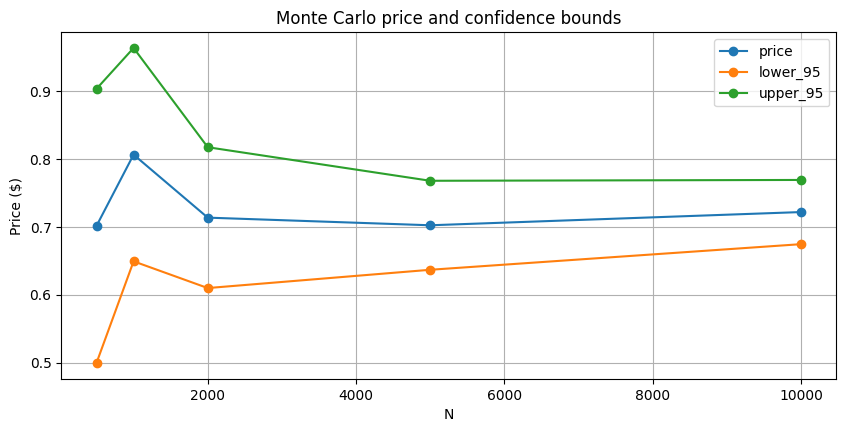

In [3]:
records=[]
for nn in [500,1000,2000,5000,10000]:
    q=barrier_mc(s0,K,B,r,T,sigma,n=nn,steps=63,seed=41)
    records.append({'N':nn,'price':q['price'],'lower_95':q['ci_low'],'upper_95':q['ci_high'],'SE':q['stderr']})
convergence=pd.DataFrame(records)
display(convergence.round(5))
ax=convergence.plot(x='N',y=['price','lower_95','upper_95'],marker='o',title='Monte Carlo price and confidence bounds')
ax.set_ylabel('Price ($)');plt.show()

## Sensitivities close to the upper barrier

With common random numbers for bumped evaluations,

\[\Delta\approx\frac{V(S+h)-V(S-h)}{2h},\quad\nu\approx\frac{V(\sigma+h_\sigma)-V(\sigma-h_\sigma)}{2h_\sigma}.\]

Vega here is **price change per 1.00 absolute volatility**, not per 1 vol-point. Near a knock-out threshold, the option's delta can become negative as a rising spot raises the probability of knock-out. These finite differences may still be noisy.

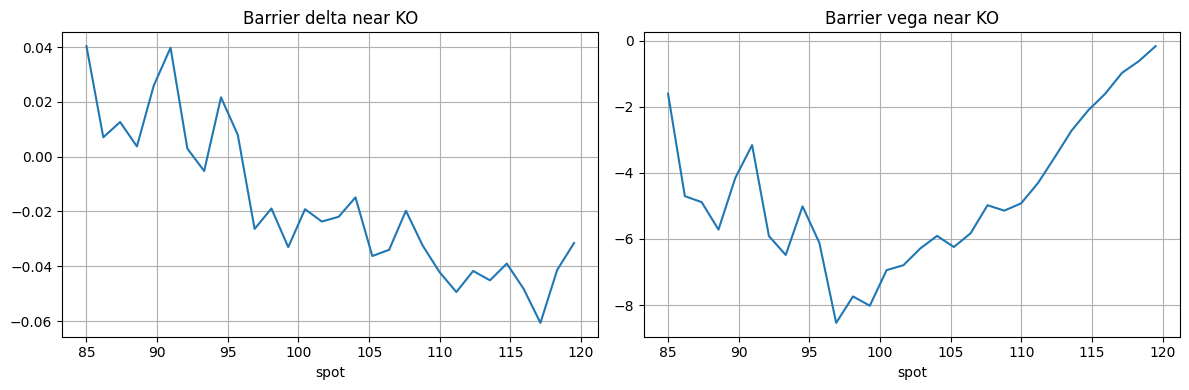

In [4]:
grid=np.linspace(85,119.5,30)
zz=shocks(2000,63,1,seed=41)
sens=pd.DataFrame([{'spot':ss,**barrier_greeks(ss,K,B,r,T,sigma,zz)} for ss in grid])
fig,axs=plt.subplots(1,2,figsize=(12,4))
sens.plot(x='spot',y='delta',ax=axs[0],legend=False,title='Barrier delta near KO')
sens.plot(x='spot',y='vega',ax=axs[1],legend=False,title='Barrier vega near KO')
plt.tight_layout();plt.show()

## Dynamic hedging: 21 trading days

Let \(q_B=-1000\) be the desk's short barrier-option position. The vanilla call position \(q_C\) and stock position \(h_S\) are chosen daily to approximately cancel **vega** and **delta**:

\[q_C=-q_B\frac{\nu_B}{\nu_C},\qquad h_S=-q_B\Delta_B-q_C\Delta_C.\]

At each day-end, the simulation marks the prior day's stock and vanilla exposures to current prices, adds the short barrier mark-to-market, subtracts current turnover fees, and rebalances. This design avoids applying newly established hedges to yesterday's market move.

**Knock-outs on the realized path** are checked at four subobservations per day; continuous-monitoring bridge correction is used in pricing but not to sample the realized hit event. We disclose this distinction instead of claiming fully continuous hedge-path monitoring.

,day,spot,barrier_price,delta,vega,stock_hedge,vanilla_hedge,daily_pnl,cumulative_pnl
0,0,100.0000,0.7137,-0.0349,-7.8608,82.0443,-201.2262,-1.0392,-1.0392
1,1,99.6054,0.7311,-0.0326,-8.0135,85.6092,-205.6981,0.7654,-0.2737
2,2,101.2442,0.6922,-0.0236,-6.9663,83.7096,-178.8324,-14.1458,-14.4195
3,3,103.8254,0.6452,-0.0123,-5.8126,83.7547,-150.3487,-18.7651,-33.1846
4,4,102.8113,0.6644,-0.0279,-6.6332,78.9532,-171.3219,-4.4202,-37.6049
5,5,102.1269,0.6817,-0.0171,-6.5110,86.0616,-168.2510,5.1435,-32.4614
6,6,100.6702,0.7178,-0.0205,-7.0898,87.8596,-183.4430,-9.9294,-42.3908
7,7,98.1367,0.7909,-0.0219,-8.1225,94.7661,-212.0816,-26.3602,-68.7510
8,8,98.2646,0.7922,-0.0208,-8.0683,95.6322,-210.9513,0.7705,-67.9805
9,9,98.4694,0.7921,-0.0194,-7.9833,96.5968,-208.9439,0.5893,-67.3912


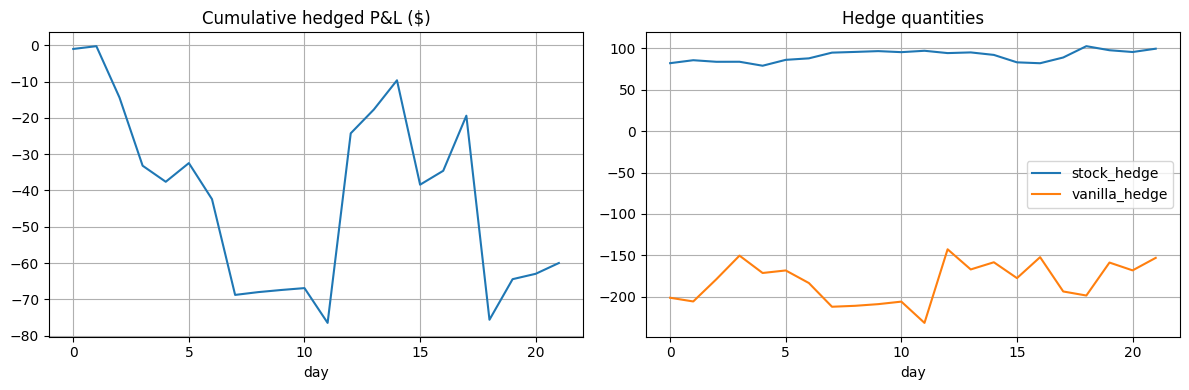

Final P&L: -59.97
Transaction costs: 2.2
P&L standard deviation: 20.63


In [5]:
hedge=simulate_barrier_hedge(days=21,s0=s0,k=K,barrier=B,r=r,t=T,sigma=sigma,
                             n=2000,seed=31,contracts=-1000,cost_bps=1.,hedge_vega=True)
display(hedge[['day','spot','barrier_price','delta','vega','stock_hedge','vanilla_hedge','daily_pnl','cumulative_pnl']].round(4))
fig,axs=plt.subplots(1,2,figsize=(12,4))
hedge.plot(x='day',y='cumulative_pnl',ax=axs[0],legend=False,title='Cumulative hedged P&L ($)')
hedge.plot(x='day',y=['stock_hedge','vanilla_hedge'],ax=axs[1],title='Hedge quantities')
plt.tight_layout();plt.show()
print('Final P&L:',round(hedge.cumulative_pnl.iloc[-1],2))
print('Transaction costs:',round(hedge.cost.sum(),2))
print('P&L standard deviation:',round(hedge.daily_pnl.iloc[1:].std(),2))

## Vega hedge versus delta-only hedge

The following comparison uses the same underlying realized path and Monte Carlo shocks; compare absolute P&L volatility rather than assuming that two-factor hedging *always* improves performance (transaction costs and hedging-instrument basis can matter).

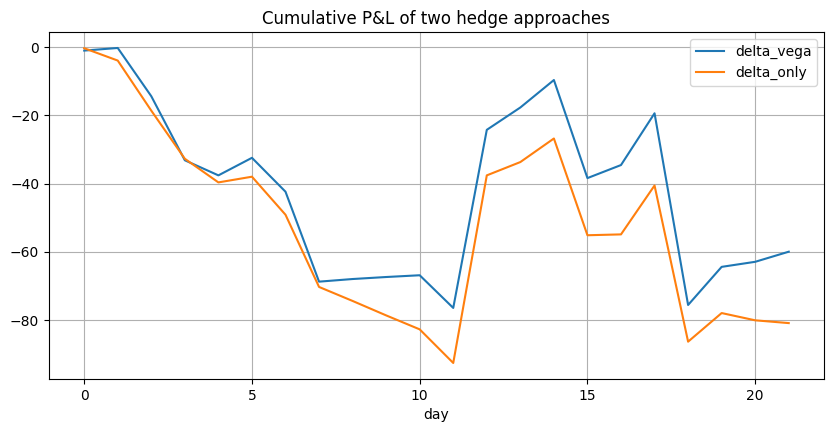

Daily P&L vol — delta-vega: 20.63
Daily P&L vol — delta-only: 18.91


In [6]:
d_only=simulate_barrier_hedge(days=21,s0=s0,k=K,barrier=B,r=r,t=T,sigma=sigma,n=2000,seed=31,contracts=-1000,cost_bps=1.,hedge_vega=False)
comp=pd.DataFrame({'day':hedge.day,'delta_vega':hedge.cumulative_pnl,'delta_only':d_only.cumulative_pnl})
comp.plot(x='day',y=['delta_vega','delta_only'],title='Cumulative P&L of two hedge approaches');plt.show()
print('Daily P&L vol — delta-vega:',round(hedge.daily_pnl.iloc[1:].std(),2))
print('Daily P&L vol — delta-only:',round(d_only.daily_pnl.iloc[1:].std(),2))

## Model validation and Streamlit delivery

Sanity checks: immediate knock-out produces zero price; the barrier call is less valuable than an otherwise identical vanilla call; simulation convergence can be examined from the price/CI table. These are *necessary*, not sufficient, checks.

Run `streamlit run app_03_barrier_hedging.py`. Interactive features: Greeks, barrier-sensitive charts, confidence intervals, hedging inventory, turnover costs, CSV export and a toggled vega hedge. Because Monte Carlo Greeks get noisy near barriers, no result should be interpreted as a guaranteed replication strategy.

**Interview discussion:** digital-like delta behavior near barrier, volatility smile risk, jump-to-knock-out losses, why vanilla vega cannot hedge barrier surface exposure perfectly, execution and model-risk limits.

In [7]:
assert barrier_mc(120,100,120,.02,1,.25)['price']==0
assert 0 <= mark['price'] <= van['price']+1.e-8
print('Basic valuation sanity checks passed')

Basic valuation sanity checks passed
